## Generating the datasets' metadata and actual relations

The cell below generates `total_datasets_to_be_generated` datasets. No input data is generated yet. For each dataset, it randomly picks:

- **dimension**: the number of features (1 to 9)
- **samples size**: the number of samples (100 to 4999)
- **noise intensity**: a value between 0 (low noise) and 1 (high noise), not applied yet
- **relation**: `linear` or `non-linear`, using the probabilities in `relation_probabilities`

Then it builds the **actual relation**, the function the regressor will later try to estimate:

- **linear**: $y = w_0 + w_1 x_1 + \dots + w_d x_d$
- **non-linear** (the generalized linear form from the lecture): $y = w_0 + w_1 \phi_1(x_1) + \dots + w_d \phi_d(x_d)$, where each feature gets its own function $\phi_j$, picked randomly from `non_linear_functions` (a polynomial of degree 2 to 10, sin, cos, log, sqrt, abs, tanh, sigmoid or gaussian)

The weights $w_0, \dots, w_d$ are picked randomly between -10 and 10. Each dataset is stored in `datasets` as a tuple:
`(dimension, samples_size, noise_intensity, relation, weights, actual_relation, formula)`, where `formula` is a readable version of the relation. Finally, the cell prints every dataset's metadata.

In [4]:
import numpy as np
from numpy.random import PCG64

total_datasets_to_be_generated = 10

rng = np.random.Generator(PCG64())

relation_types = ("linear", "non-linear")
relation_probabilities = [0.8, 0.2]

non_linear_functions = {
    "polynomial": lambda x, degree: x ** degree,
    "sin": lambda x: np.sin(x),
    "cos": lambda x: np.cos(x),
    "log": lambda x: np.log(np.abs(x) + 1),
    "sqrt": lambda x: np.sqrt(np.abs(x)),
    "abs": lambda x: np.abs(x),
    "tanh": lambda x: np.tanh(x),
    "sigmoid": lambda x: 1 / (1 + np.exp(-x)),
    "gaussian": lambda x: np.exp(-x ** 2 / 2),
}

datasets = []

for _ in range(total_datasets_to_be_generated):
    dimension = int(9 * rng.random(size=None) + 1)

    samples_size = int(4900 * rng.random(size=None) + 100)

    noise_intensity = rng.random(size=None)

    relation = rng.choice(relation_types, p=relation_probabilities)

    actual_relation = None

    if relation == "linear":
        weights = rng.uniform(-10, 10, size=dimension + 1)
        actual_relation = lambda X, weights=weights: weights[0] + X @ weights[1:]
        formula = f"y = {weights[0]:.2f}"
        for j in range(dimension):
            formula += f" + ({weights[j + 1]:.2f})·x{j + 1}"
    else:
        weights = rng.uniform(-10, 10, size=dimension + 1)
        feature_functions = []
        formula = f"y = {weights[0]:.2f}"
        for j in range(dimension):
            name = rng.choice(list(non_linear_functions))
            if name == "polynomial":
                degree = int(rng.integers(2, 11))
                feature_functions.append(lambda x, degree=degree: non_linear_functions["polynomial"](x, degree))
                formula += f" + ({weights[j + 1]:.2f})·x{j + 1}^{degree}"
            else:
                feature_functions.append(non_linear_functions[name])
                formula += f" + ({weights[j + 1]:.2f})·{name}(x{j + 1})"
        actual_relation = lambda X, weights=weights, feature_functions=feature_functions, dimension=dimension: weights[0] + sum(weights[j + 1] * feature_functions[j](X[:, j]) for j in range(dimension))

    datasets.append((dimension, samples_size, noise_intensity, relation, weights, actual_relation, formula))

for i, (dimension, samples_size, noise_intensity, relation, weights, actual_relation, formula) in enumerate(datasets):
    print(f"dataset {i + 1}:")
    print(f"  dimension:       {dimension}")
    print(f"  samples size:    {samples_size}")
    print(f"  noise intensity: {noise_intensity:.2f}")
    print(f"  relation:        {relation}")
    print(f"  weights:         {weights}")
    print(f"  formula:         {formula}")

dataset 1:
  dimension:    1
  samples size: 4748
  noise:        0.63
  relation:     linear
  weights:      [ 8.7531644  -0.10730634]
  formula:      y = 8.75 + (-0.11)·x1
dataset 2:
  dimension:    1
  samples size: 2368
  noise:        0.16
  relation:     linear
  weights:      [6.41880368 6.90881034]
  formula:      y = 6.42 + (6.91)·x1
dataset 3:
  dimension:    4
  samples size: 2953
  noise:        0.11
  relation:     linear
  weights:      [ 6.32360161 -8.27931217  9.98886144 -6.27164003  7.61117308]
  formula:      y = 6.32 + (-8.28)·x1 + (9.99)·x2 + (-6.27)·x3 + (7.61)·x4
dataset 4:
  dimension:    7
  samples size: 3102
  noise:        0.11
  relation:     linear
  weights:      [-9.74413744 -9.74618822  6.49146812 -7.16163922  7.25373246 -4.01103399
  4.729886    6.37595243]
  formula:      y = -9.74 + (-9.75)·x1 + (6.49)·x2 + (-7.16)·x3 + (7.25)·x4 + (-4.01)·x5 + (4.73)·x6 + (6.38)·x7
dataset 5:
  dimension:    1
  samples size: 1334
  noise:        0.19
  relation:    

## Generating the sample data

The cell below uses each dataset's metadata to generate its samples:

- **inputs** `X`: a `samples_size × dimension` matrix, each value picked uniformly between -1000 and 1000
- **clean outputs** `y_clean`: the actual relation applied to the inputs, $f(\mathbf{x})$
- **noisy outputs** `y`: the clean outputs plus Gaussian noise, $y = f(\mathbf{x}) + \varepsilon$, where $\varepsilon \sim \mathcal{N}(0, \sigma^2)$

The noise's standard deviation is scaled to each dataset's outputs: $\sigma = \text{noise\_intensity} \times \text{std}(y_{clean})$. This way `noise_intensity` means the same in every dataset, whatever the size of its outputs: 0 means no noise, 0.5 means noise about half as large as the spread of the outputs, and 1 means noise as large as the spread itself.

### Why the noise is random and not a constant

Adding the same constant $c$ to every target value is not real noise. It only shifts the whole relation: $y = f(\mathbf{x}) + c$, which is the same as changing the bias from $w_0$ to $w_0 + c$. That is a new, perfectly regular pattern, so the regressor would learn it exactly and none of it would count as error. Real noise is different for each sample, unpredictable from the input, and averages out to zero. That's why a separate random value $\varepsilon$ is drawn for every sample.

The samples are stored in `samples` as `(X, y)` tuples, in the same order as `datasets`, so `samples[i]` belongs to `datasets[i]`. They are also added to each dataset's tuple as an 8th field, so every tuple in `datasets` becomes:
`(dimension, samples_size, noise_intensity, relation, weights, actual_relation, formula, (X, y))`.

Finally, the cell prints the first 15 patterns of each dataset and, for every 1-dimensional dataset, draws a scatter plot of its samples ($x_1$ against $y$). Only 1-dimensional datasets are plotted, because data with more features can't be drawn on a 2D plot; the other datasets are only printed.

dataset 1:
  x = [  -531.20]  ->  y = 69.11
  x = [  -246.51]  ->  y = -8.55
  x = [  -594.47]  ->  y = 76.90
  x = [   639.64]  ->  y = -3.54
  x = [  -842.64]  ->  y = 85.96
  x = [     3.08]  ->  y = -3.93
  x = [  -228.58]  ->  y = 75.93
  x = [  -382.31]  ->  y = 91.93
  x = [   825.78]  ->  y = -63.79
  x = [   460.11]  ->  y = -50.75
  x = [  -353.99]  ->  y = 41.72
  x = [  -877.66]  ->  y = 77.57
  x = [  -822.05]  ->  y = 153.18
  x = [   799.13]  ->  y = -106.45
  x = [  -244.62]  ->  y = -24.24
dataset 2:
  x = [   842.17]  ->  y = 6958.74
  x = [  -339.26]  ->  y = -1288.39
  x = [  -674.70]  ->  y = -5170.08
  x = [   416.75]  ->  y = 2772.59
  x = [   812.45]  ->  y = 5571.07
  x = [  -676.43]  ->  y = -5129.10
  x = [  -914.92]  ->  y = -5496.94
  x = [   283.63]  ->  y = 1575.24
  x = [  -447.66]  ->  y = -3898.96
  x = [   668.43]  ->  y = 3732.18
  x = [   476.84]  ->  y = 4000.12
  x = [   580.24]  ->  y = 3977.32
  x = [   589.99]  ->  y = 3963.18
  x = [   805.72]

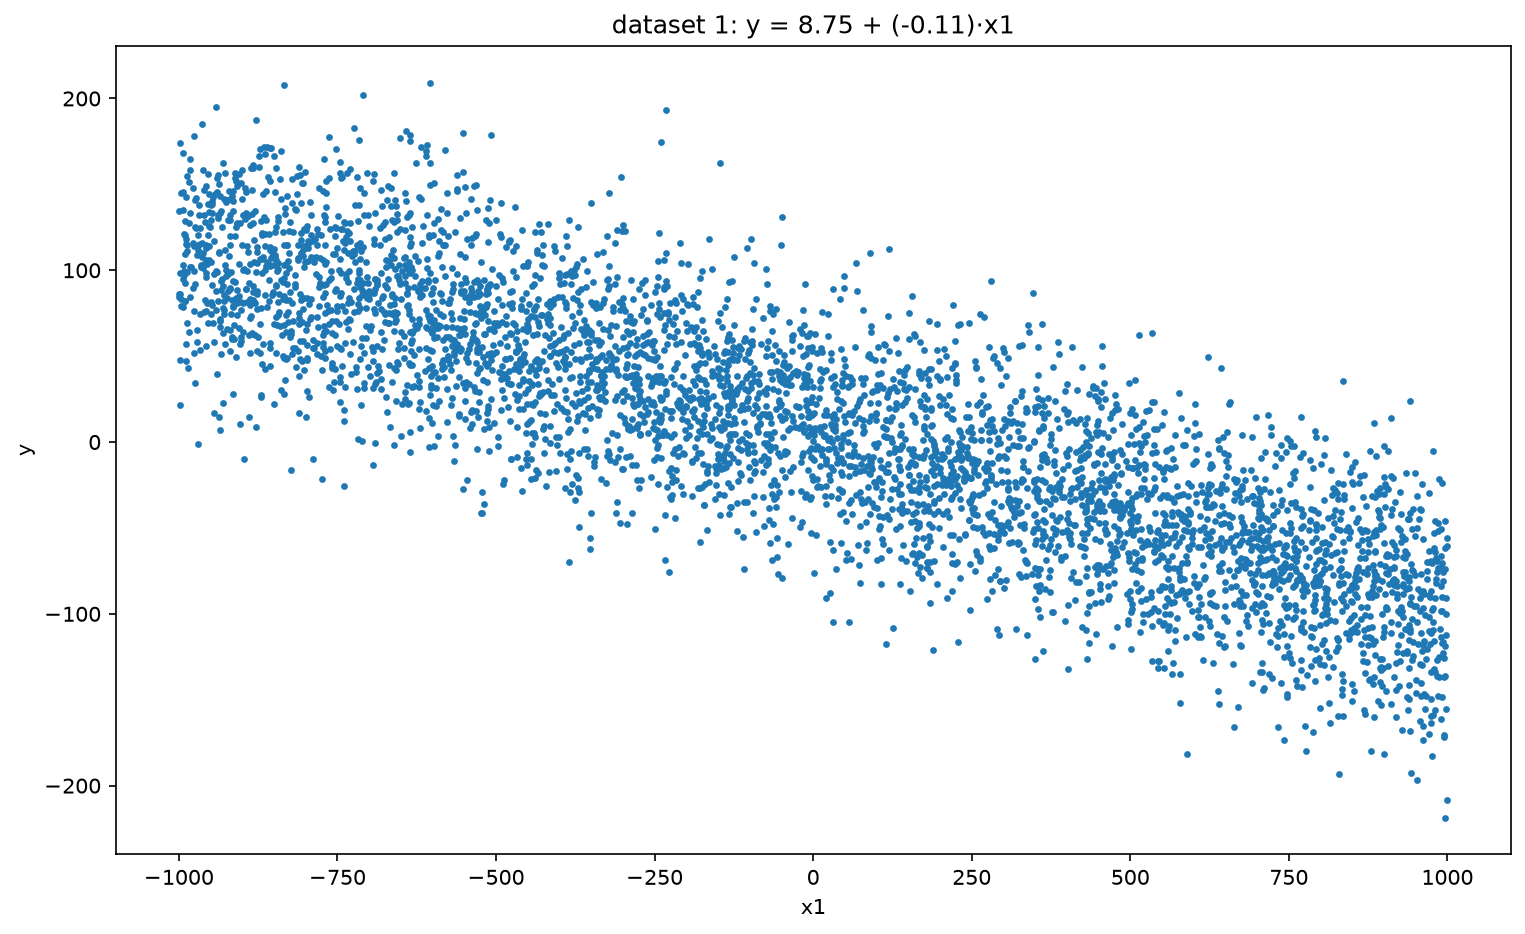

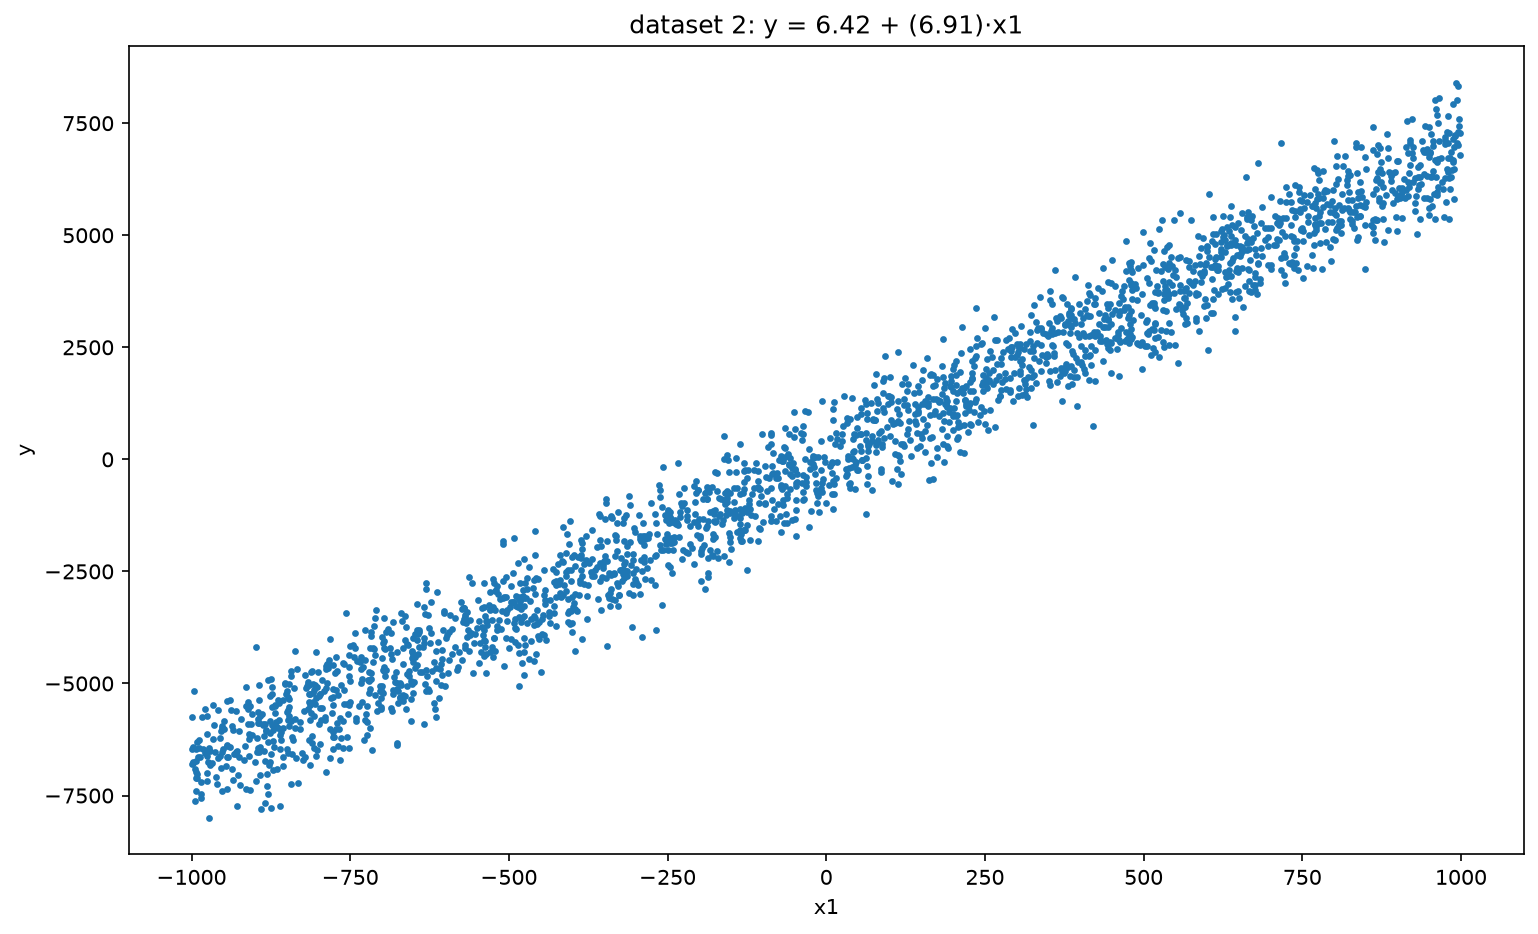

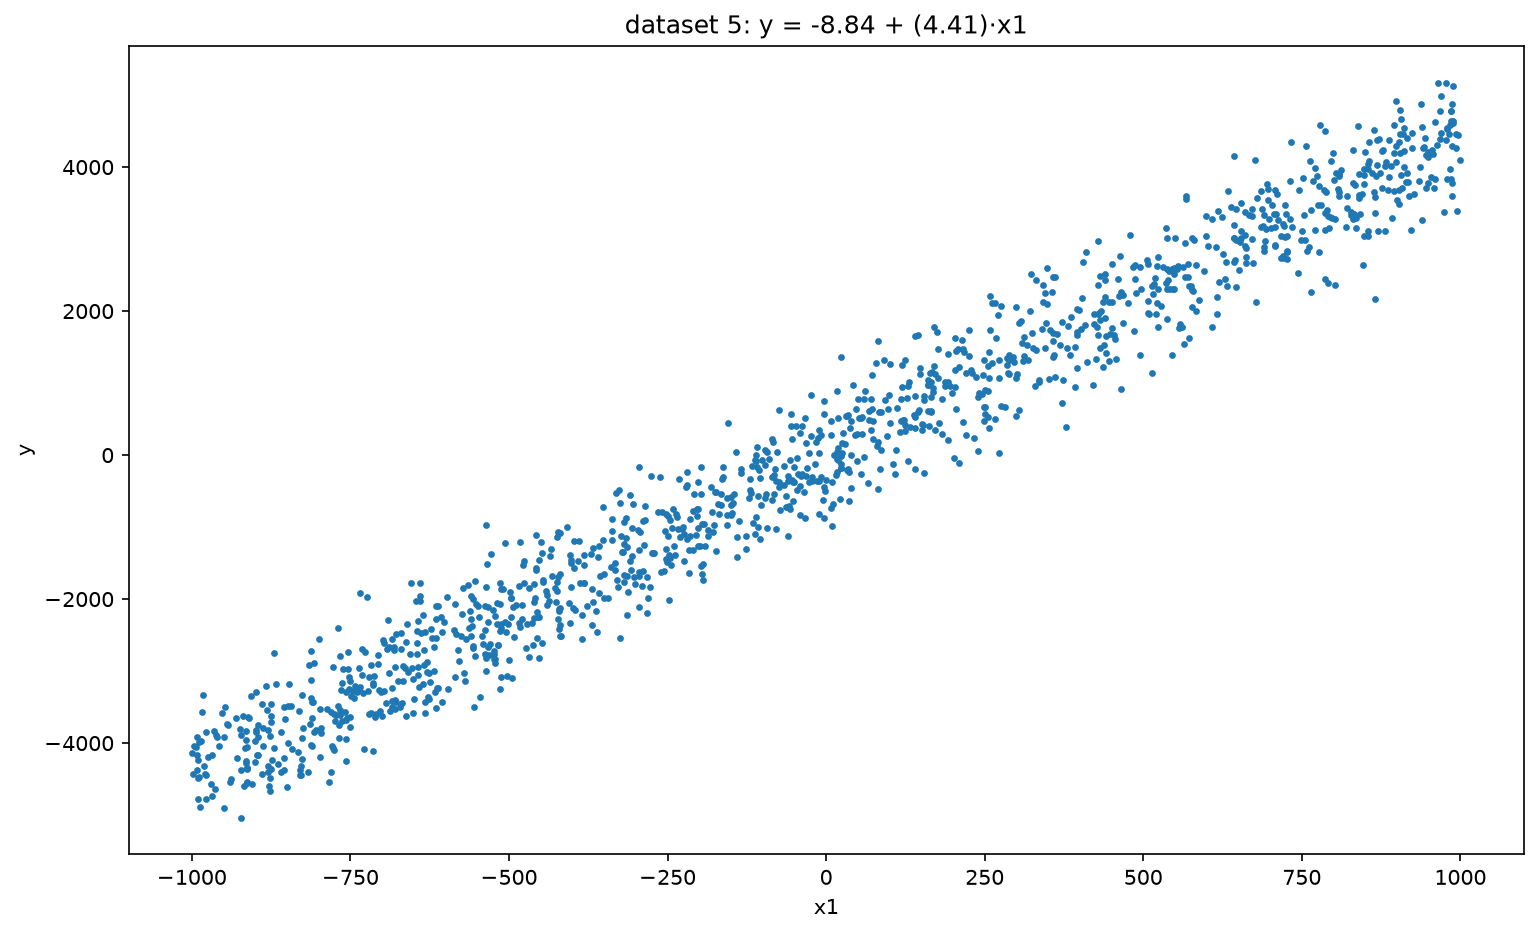

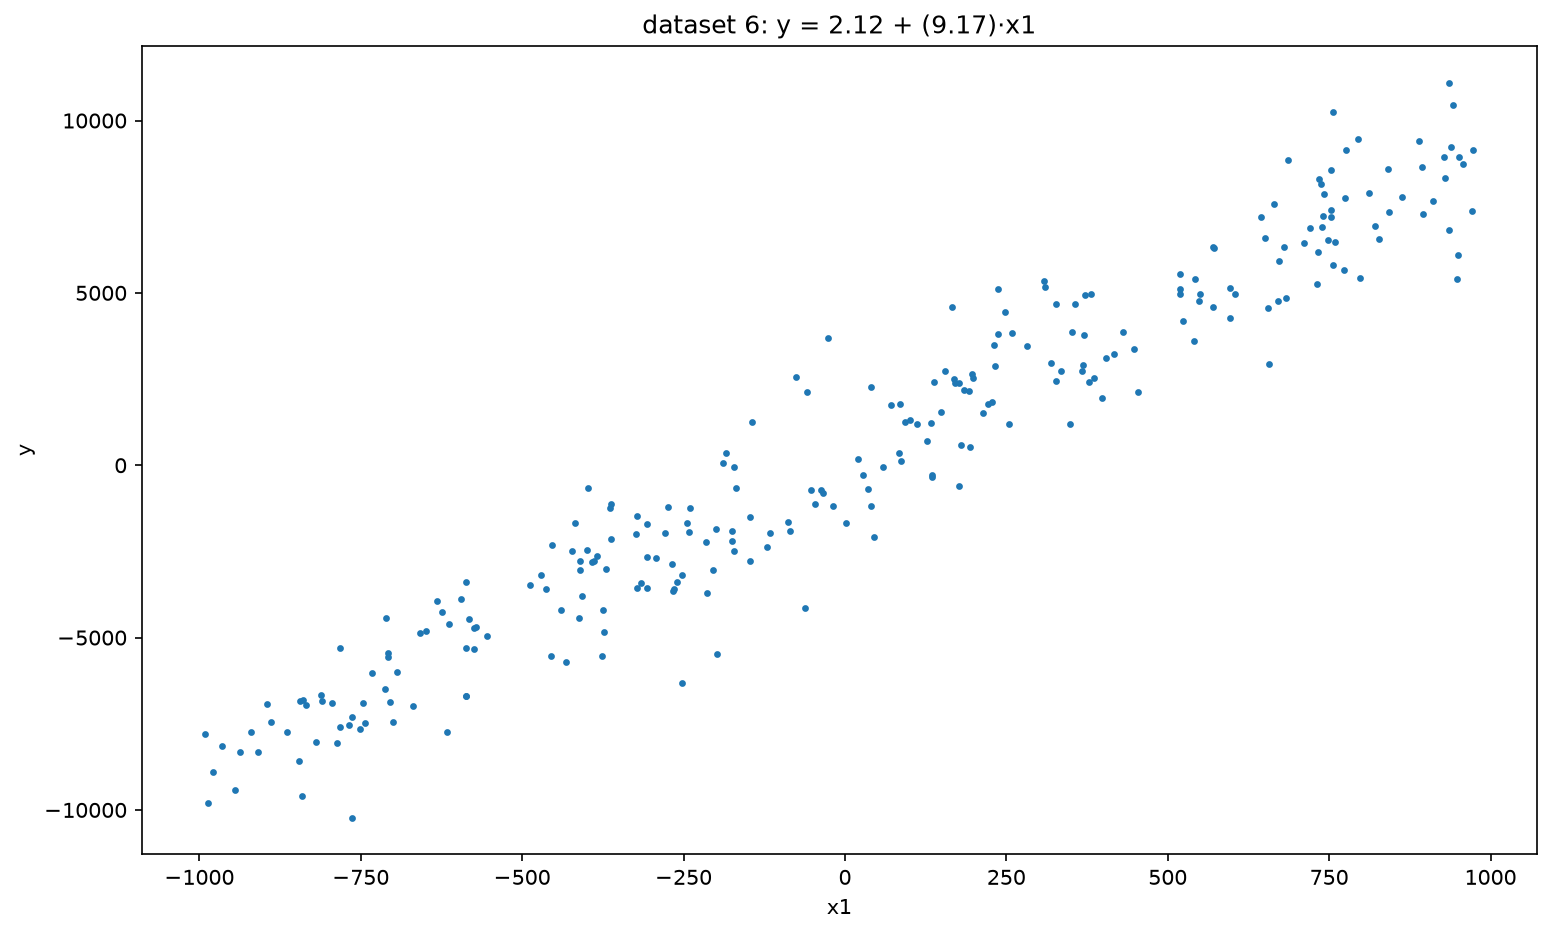

In [11]:
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (12, 7)
plt.rcParams["figure.dpi"] = 150

samples = []

for i in range(len(datasets)):
    dimension, samples_size, noise_intensity, relation, weights, actual_relation, formula = datasets[i][:7]
    X = rng.uniform(-1000, 1000, size=(samples_size, dimension))
    y_clean = actual_relation(X)
    noise_std = noise_intensity * np.std(y_clean)
    y = y_clean + rng.normal(0, noise_std, size=samples_size)
    samples.append((X, y))
    datasets[i] = datasets[i][:7] + ((X, y),)

for i, (X, y) in enumerate(samples):
    print(f"dataset {i + 1}:")
    for k in range(15):
        features = ", ".join(f"{value:9.2f}" for value in X[k])
        print(f"  x = [{features}]  ->  y = {y[k]:.2f}")

one_dimensional_found = False

for i, (dimension, samples_size, noise_intensity, relation, weights, actual_relation, formula, (X, y)) in enumerate(datasets):
    if dimension == 1:
        one_dimensional_found = True
        plt.figure()
        plt.scatter(X[:, 0], y, s=5)
        plt.title(f"dataset {i + 1}: {formula}")
        plt.xlabel("x1")
        plt.ylabel("y")
        plt.show()

if not one_dimensional_found:
    print("there are no 1-dimensional datasets to visualize")

## 10-fold cross validation and linear regression

The cell below finds a linear regressor for every dataset and measures its error with $k$-fold cross validation ($k = 10$):

1. A column of ones is added in front of `X` (`X_with_bias`) so the bias $w_0$ is learned as well.
2. The samples are divided into 10 folds. In each of the 10 iterations, one fold is the **test** data and the other 9 are the **training** data, so every sample is used for testing exactly once.
3. On the training data, the regressor is found with the least squares (normal equation) method from the lecture: $\mathbf{w} = (X^T X)^{-1} X^T \mathbf{y}$.
4. On the test data, the regressor's error is measured. Every test sample has the same weight $\frac{1}{n}$:
   - $RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n} (\hat{y}_i - y_i)^2}$
   - $MAE = \frac{1}{n}\sum_{i=1}^{n} |y_i - \hat{y}_i|$
   - $MAPE = \frac{1}{n}\sum_{i=1}^{n} \left|\frac{y_i - \hat{y}_i}{y_i}\right| \cdot 100\%$. It becomes very large when some targets are close to 0, because it divides by each $y_i$.
   - $R^2 = 1 - \frac{\sum_{i}(y_i - \hat{y}_i)^2}{\sum_{i}(y_i - \bar{y})^2}$, the coefficient of determination: 1 is a perfect fit, 0 is no better than always predicting the mean $\bar{y}$
5. Each error is averaged over the 10 folds: $E = \frac{1}{10}\sum_{i=1}^{10} E_i$.

The results are stored in `cross_validation_results`, in the same order as `datasets`. Each entry is `(fold_results, average_rmse, average_mae, average_mape, average_r2)`, where `fold_results` holds `(w, rmse, mae, mape, r2)` for each fold.

For every dataset, the cell prints each fold's errors with its estimated regressor, then the averages. Only 1-dimensional datasets are plotted: for them, the cell also draws the samples together with the 10 regression lines. Datasets with more dimensions are only printed.

dataset 1: y = 8.75 + (-0.11)·x1
samples size: 4748, noise intensity: 0.63
    fold           RMSE            MAE       MAPE (%)         R²   estimated regressor
       1        39.4719        30.9779       223.8622     0.7100   y = 8.7935 + (-0.1059)·x1
       2        40.8957        32.6960       193.5616     0.6996   y = 8.7729 + (-0.1058)·x1
       3        37.8553        30.3806       214.4452     0.7244   y = 8.8314 + (-0.1060)·x1
       4        38.8444        31.0611       200.7299     0.7017   y = 8.5213 + (-0.1056)·x1
       5        37.6246        29.5261       133.2635     0.7248   y = 8.9348 + (-0.1060)·x1
       6        40.0549        32.0173       169.0253     0.7106   y = 8.9828 + (-0.1058)·x1
       7        41.6683        33.3349       205.2065     0.6769   y = 8.7029 + (-0.1062)·x1
       8        38.3795        29.9764       125.5720     0.6999   y = 8.6033 + (-0.1064)·x1
       9        38.5081        31.1138       181.8881     0.7142   y = 8.7287 + (-0.1061)·x1
 

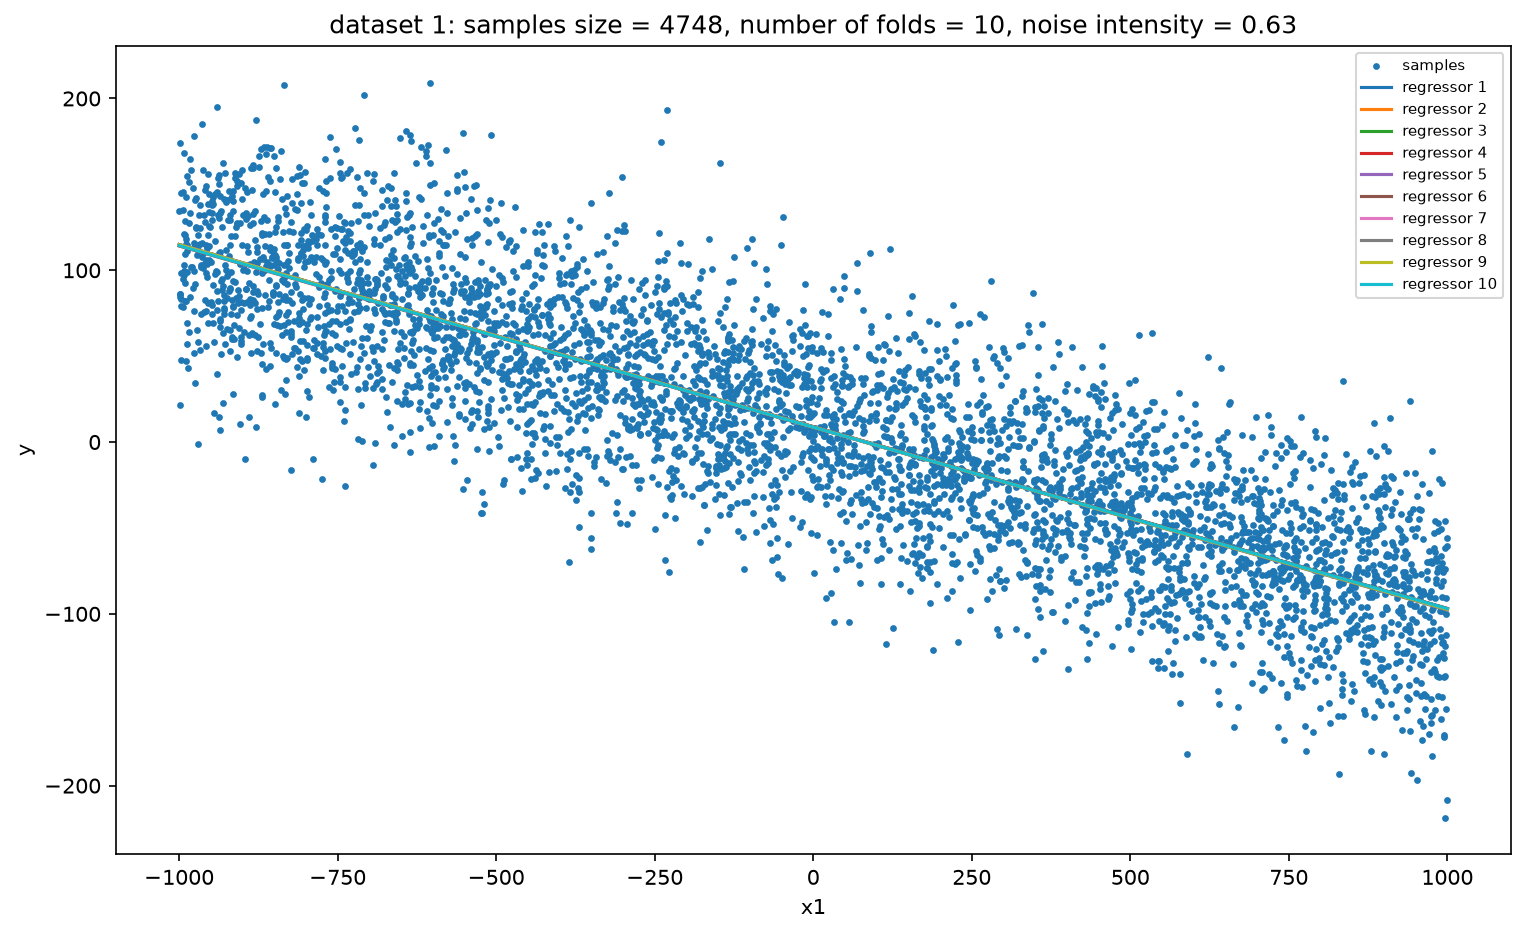


dataset 2: y = 6.42 + (6.91)·x1
samples size: 2368, noise intensity: 0.16
    fold           RMSE            MAE       MAPE (%)         R²   estimated regressor
       1       651.6745       536.2825        56.4008     0.9741   y = 9.2862 + (6.9108)·x1
       2       611.6755       494.5247        33.8228     0.9779   y = 15.1298 + (6.9007)·x1
       3       704.5142       569.3192        65.6484     0.9697   y = 16.3337 + (6.9110)·x1
       4       615.8924       496.4587        31.2945     0.9779   y = 4.9317 + (6.9099)·x1
       5       676.0105       556.7435        86.8868     0.9716   y = 12.0753 + (6.9205)·x1
       6       613.9224       485.5608       124.4970     0.9759   y = 11.3958 + (6.9092)·x1
       7       660.2174       534.6235        51.4752     0.9716   y = 16.0996 + (6.9104)·x1
       8       673.8864       554.3584        78.7187     0.9720   y = 25.0756 + (6.9065)·x1
       9       663.0937       535.8077        52.2647     0.9736   y = 17.7855 + (6.9174)·x1
   

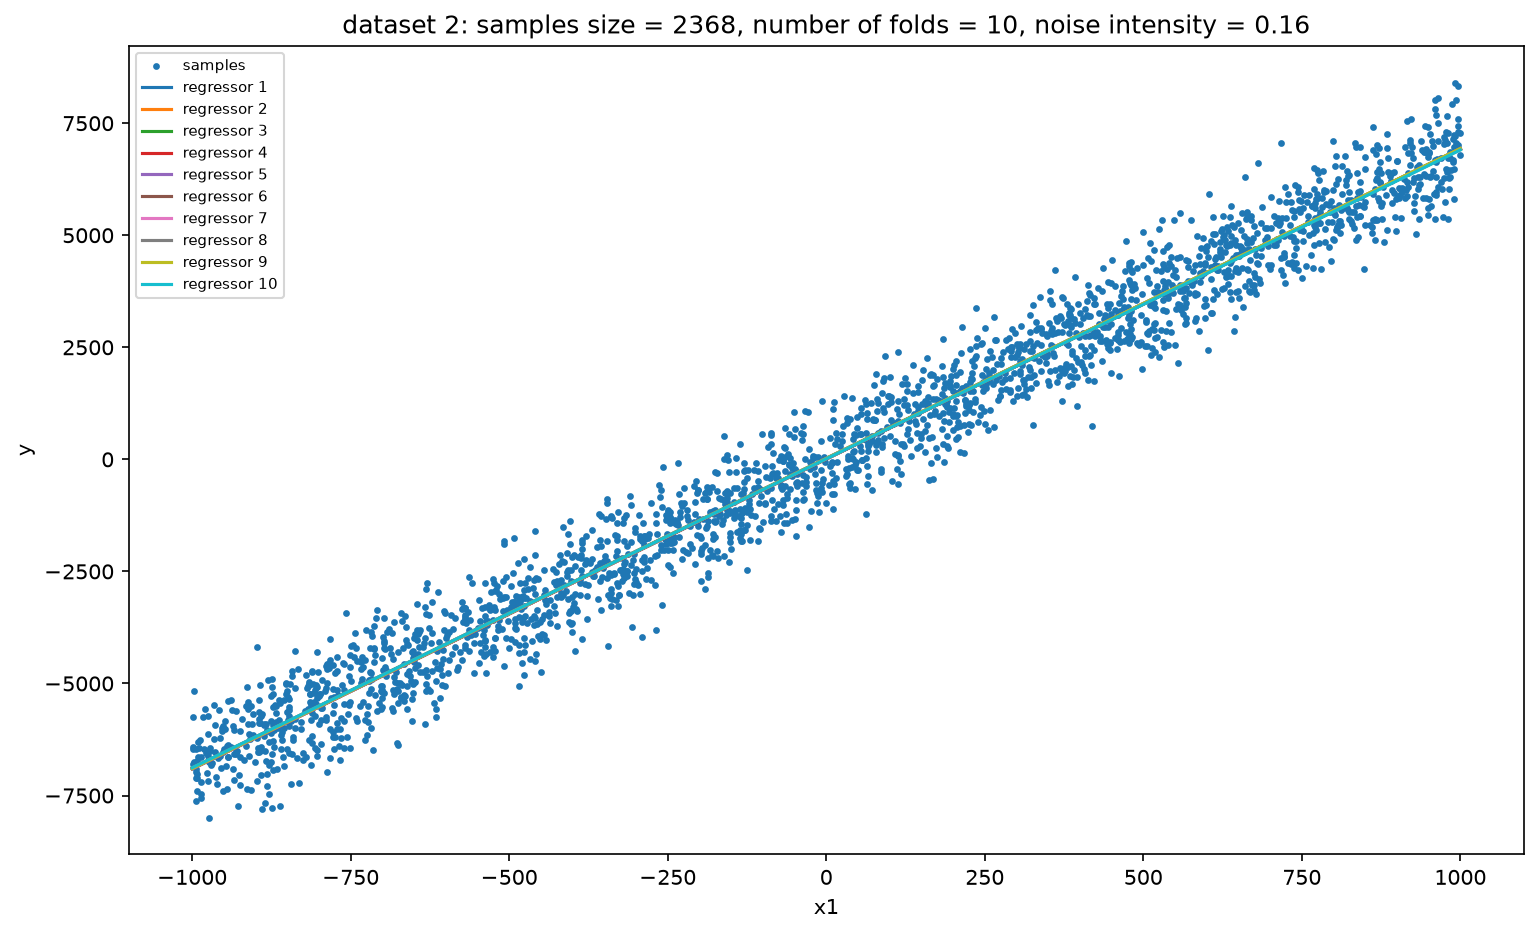


dataset 3: y = 6.32 + (-8.28)·x1 + (9.99)·x2 + (-6.27)·x3 + (7.61)·x4
samples size: 2953, noise intensity: 0.11
    fold           RMSE            MAE       MAPE (%)         R²   estimated regressor
       1      1143.6282       927.9637        69.9008     0.9845   y = 20.2110 + (-8.2910)·x1 + (10.0543)·x2 + (-6.2443)·x3 + (7.6355)·x4
       2      1036.0524       803.2590        28.1024     0.9884   y = 18.9798 + (-8.2930)·x1 + (10.0268)·x2 + (-6.2463)·x3 + (7.6085)·x4
       3      1058.6003       831.6209        60.0919     0.9858   y = 25.8084 + (-8.2815)·x1 + (10.0556)·x2 + (-6.2545)·x3 + (7.6177)·x4
       4      1038.2922       811.8972        32.5412     0.9881   y = 21.2245 + (-8.2852)·x1 + (10.0159)·x2 + (-6.2435)·x3 + (7.6329)·x4
       5      1131.8546       923.1524       163.5514     0.9863   y = 21.1518 + (-8.2830)·x1 + (10.0397)·x2 + (-6.2473)·x3 + (7.6138)·x4
       6      1156.3617       932.6882        52.3933     0.9853   y = 1.2100 + (-8.2842)·x1 + (10.0212)·x2 + 

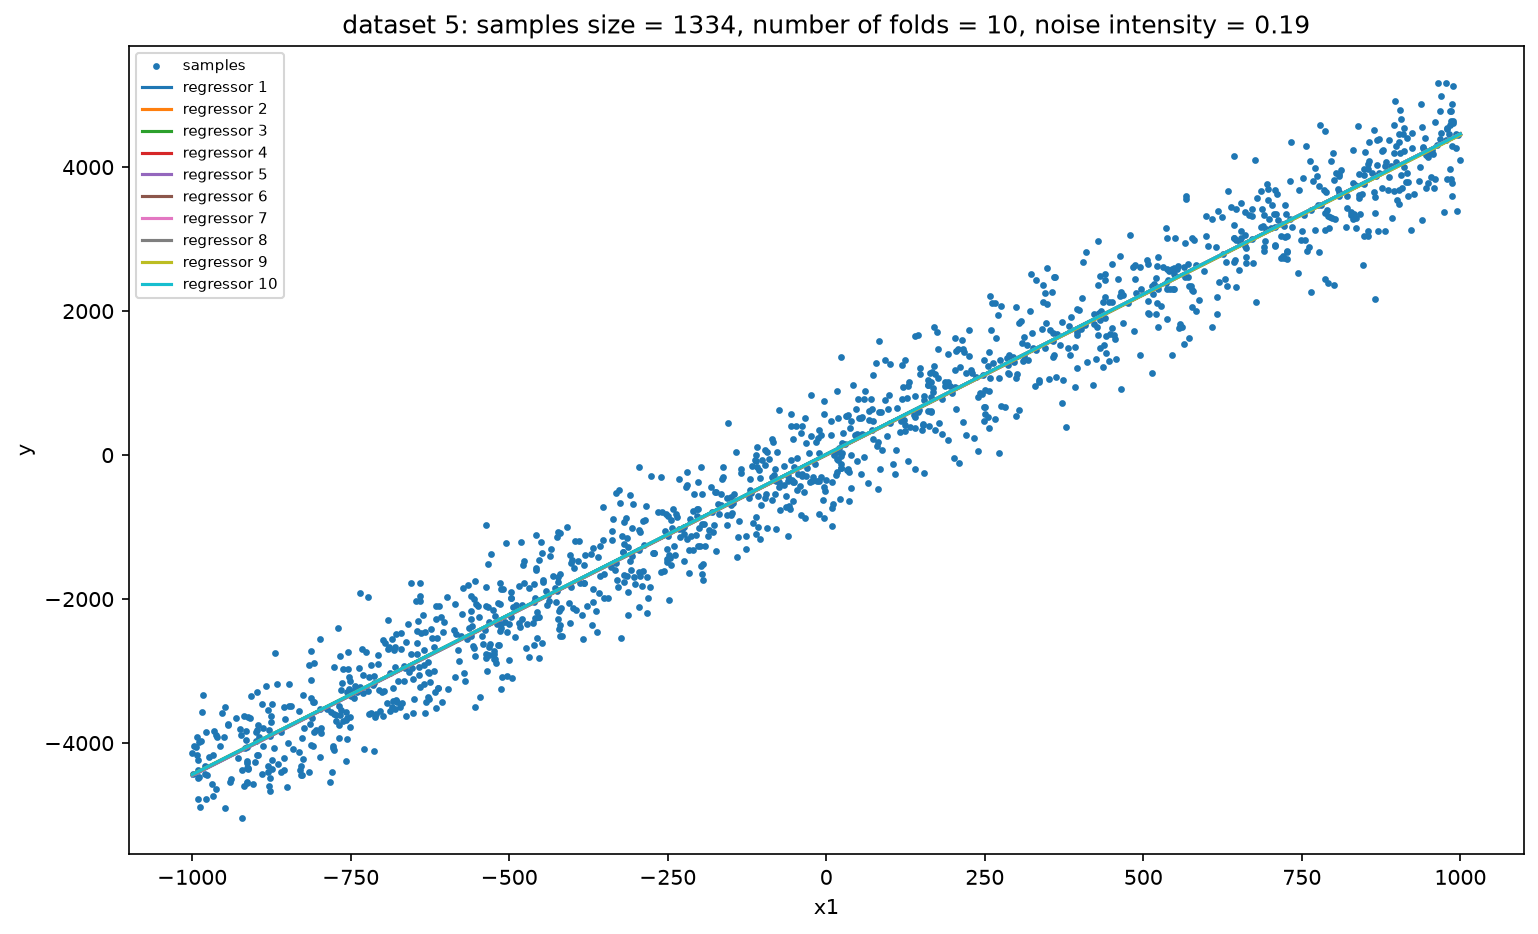


dataset 6: y = 2.12 + (9.17)·x1
samples size: 259, noise intensity: 0.26
    fold           RMSE            MAE       MAPE (%)         R²   estimated regressor
       1      1411.1068      1114.5389        43.7792     0.9137   y = 125.6072 + (9.0794)·x1
       2      1262.7919      1000.0591       136.6570     0.9337   y = 85.1006 + (9.1215)·x1
       3      1370.4432      1067.7230       132.8636     0.8708   y = 162.9964 + (9.0707)·x1
       4      1493.8688      1182.4886        58.2093     0.9225   y = 163.7946 + (8.9773)·x1
       5      1478.4621      1136.8165       108.5208     0.9019   y = 60.5908 + (9.0490)·x1
       6      1307.1705      1056.4134        38.3618     0.9512   y = 132.4775 + (9.0115)·x1
       7      1056.8720       911.0840        46.3843     0.9524   y = 99.6432 + (9.0968)·x1
       8      1332.3133      1051.7811        33.3924     0.9495   y = 73.6477 + (9.0500)·x1
       9      1126.5350       915.8769        52.6417     0.9630   y = 97.3818 + (8.9744)·x

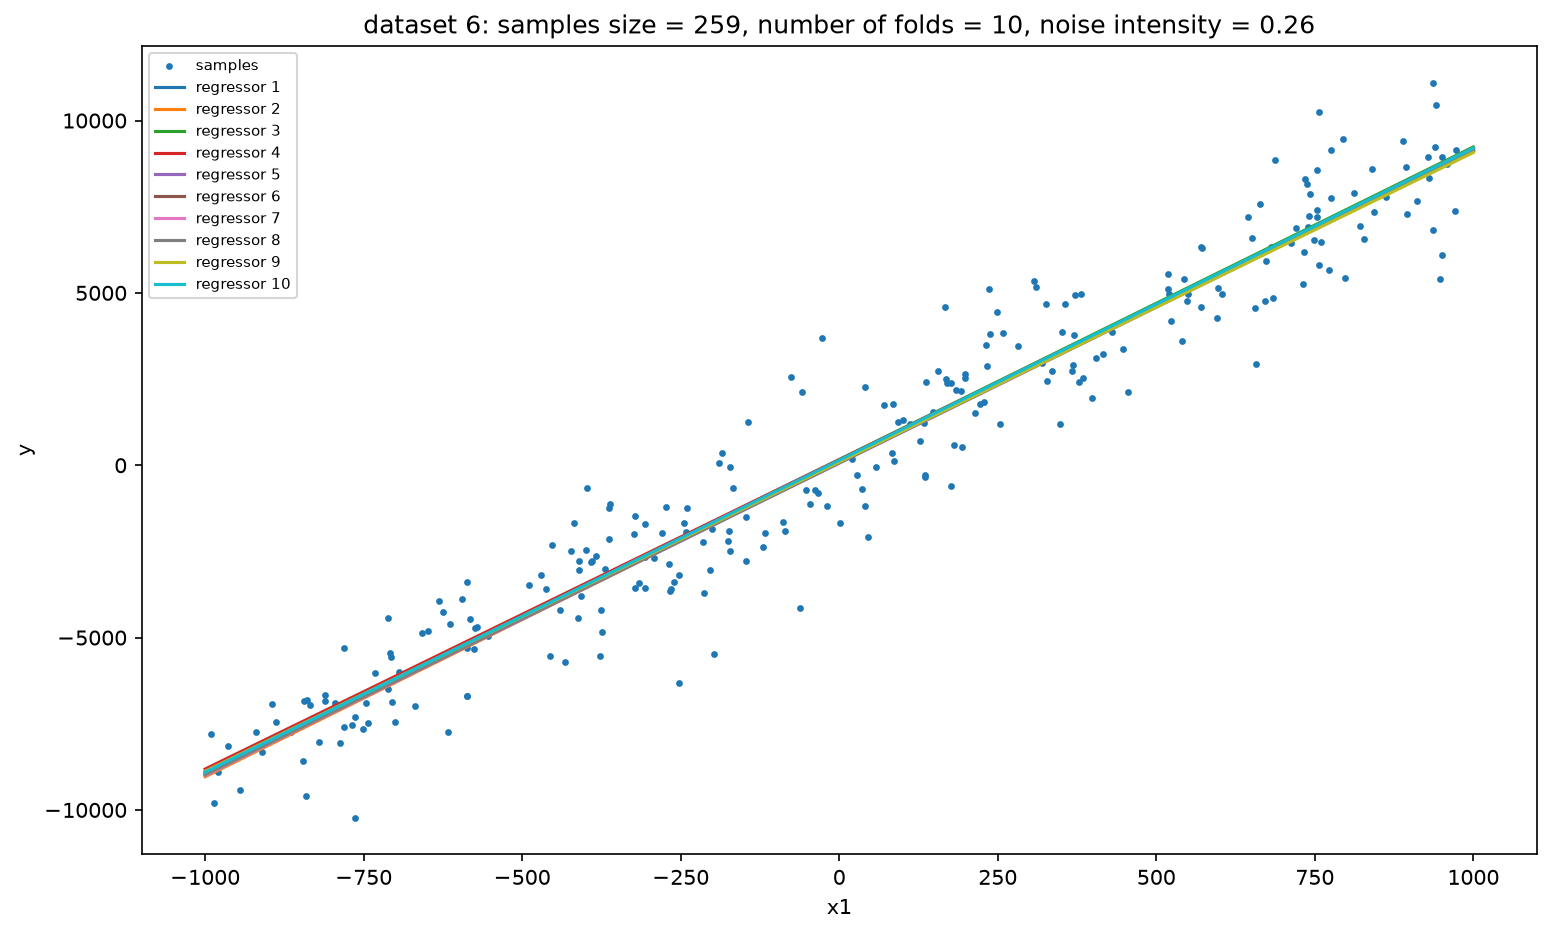


dataset 7: y = 6.71 + (0.72)·tanh(x1) + (-0.17)·abs(x2) + (-5.81)·sqrt(x3) + (6.30)·tanh(x4) + (-5.43)·x5^5 + (4.28)·sin(x6) + (8.69)·x7^4
samples size: 297, noise intensity: 0.39
    fold           RMSE            MAE       MAPE (%)         R²   estimated regressor
       1 1113172159313742.2500 839437418186134.8750       190.4598     0.7235   y = -8889119687635.3516 + (13912913414.2553)·x1 + (75283957823.9076)·x2 + (40108316482.0429)·x3 + (-147232371111.8395)·x4 + (-2273786700417.4521)·x5 + (49177856028.1619)·x6 + (-7110680891.6476)·x7
       2 1049187634402856.3750 918708072513560.6250       496.6879     0.5827   y = -51110810044436.7891 + (-20275751068.9938)·x1 + (136669139478.9899)·x2 + (93659739038.2174)·x3 + (-210727481712.8698)·x4 + (-2396284194315.6216)·x5 + (25325234749.0801)·x6 + (17645225674.5572)·x7
       3 1065105062049744.8750 838080232236728.8750       190.8031     0.3248   y = -39833209311458.4922 + (-99937349372.6785)·x1 + (47600611560.4142)·x2 + (36452013316.4699)·

In [12]:
k = 10

cross_validation_results = []

for dimension, samples_size, noise_intensity, relation, weights, actual_relation, formula, (X, y) in datasets:
    X_with_bias = np.hstack((np.ones((samples_size, 1)), X))
    folds = np.array_split(np.arange(samples_size), k)

    fold_results = []

    for f in range(k):
        test_indices = folds[f]
        train_indices = np.concatenate([folds[m] for m in range(k) if m != f])

        X_train, y_train = X_with_bias[train_indices], y[train_indices]
        X_test, y_test = X_with_bias[test_indices], y[test_indices]

        # training the linear regression model using the normal equation
        w = np.linalg.inv(X_train.T @ X_train) @ X_train.T @ y_train

        # training done, now we get to testing
        y_predicted = X_test @ w
        rmse = np.sqrt(np.mean((y_predicted - y_test) ** 2))
        mae = np.mean(np.abs(y_test - y_predicted))
        mape = np.mean(np.abs((y_test - y_predicted) / y_test)) * 100
        r2 = 1 - np.sum((y_test - y_predicted) ** 2) / np.sum((y_test - np.mean(y_test)) ** 2)

        fold_results.append((w, rmse, mae, mape, r2))

    average_rmse = np.mean([rmse for w, rmse, mae, mape, r2 in fold_results])
    average_mae = np.mean([mae for w, rmse, mae, mape, r2 in fold_results])
    average_mape = np.mean([mape for w, rmse, mae, mape, r2 in fold_results])
    average_r2 = np.mean([r2 for w, rmse, mae, mape, r2 in fold_results])

    cross_validation_results.append((fold_results, average_rmse, average_mae, average_mape, average_r2))

for i in range(len(datasets)):
    dimension, samples_size, noise_intensity, relation, weights, actual_relation, formula, (X, y) = datasets[i]
    fold_results, average_rmse, average_mae, average_mape, average_r2 = cross_validation_results[i]

    equations = []
    for w, rmse, mae, mape, r2 in fold_results:
        equation = f"y = {w[0]:.4f}"
        for j in range(dimension):
            equation += f" + ({w[j + 1]:.4f})·x{j + 1}"
        equations.append(equation)

    print(f"dataset {i + 1}: {formula}")
    print(f"samples size: {samples_size}, noise intensity: {noise_intensity:.2f}")
    print(f"{'fold':>8} {'RMSE':>14} {'MAE':>14} {'MAPE (%)':>14} {'R²':>10}   estimated regressor")
    for f, (w, rmse, mae, mape, r2) in enumerate(fold_results):
        print(f"{f + 1:>8} {rmse:>14.4f} {mae:>14.4f} {mape:>14.4f} {r2:>10.4f}   {equations[f]}")
    print(f"{'average':>8} {average_rmse:>14.4f} {average_mae:>14.4f} {average_mape:>14.4f} {average_r2:>10.4f}")

    if dimension == 1:
        plt.figure()
        plt.scatter(X[:, 0], y, s=5, label="samples")
        x_line = np.array([-1000, 1000])
        for f, (w, rmse, mae, mape, r2) in enumerate(fold_results):
            plt.plot(x_line, w[0] + w[1] * x_line, label=f"regressor {f + 1}")
        plt.title(f"dataset {i + 1}: samples size = {samples_size}, number of folds = {k}, noise intensity = {noise_intensity:.2f}")
        plt.xlabel("x1")
        plt.ylabel("y")
        plt.legend(fontsize=7)
        plt.show()

    print()